# MLB Wins — Ordinary Least Squares (OLS) Regression

**Goal.** Model a team-season's regular-season **wins (`W`)** from team statistics with an
OLS linear regression, then report (a) **evaluation metrics** and (b) **interpretable insights**.

**Data.** `csv/data.csv` (training, 1,412 team-seasons, 1904–2016, includes `W`) and
`csv/predict.csv` (400 held-out team-seasons, no `W`).

**Roadmap**
1. Data loading & overview
2. Data-quality checks and leakage flags
3. Exploratory data analysis
4. Feature engineering and train/test split
5. OLS models (nested, from parsimonious to full)
6. Evaluation metrics (in-sample, out-of-sample, cross-validated)
7. Regression diagnostics (multicollinearity, residuals)
8. Insights
9. Bonus: predictions for `predict.csv`

## 1. Setup and data loading

We use `statsmodels` for OLS (gives coefficients, standard errors, p-values, F-stat, AIC/BIC),
`scikit-learn` for metrics/CV, and `matplotlib` for charts.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera, durbin_watson

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEED = 42
DATA_PATH = "csv/data.csv"
PREDICT_PATH = "csv/predict.csv"
SUBMISSION_PATH = "csv/submission_ols.csv"

print("pandas", pd.__version__, "| numpy", np.__version__, "| statsmodels", sm.__version__)

pandas 3.0.5 | numpy 2.5.1 | statsmodels 0.15.0


In [2]:
data = pd.read_csv(DATA_PATH)
predict = pd.read_csv(PREDICT_PATH)

print("data.csv    :", data.shape)
print("predict.csv :", predict.shape)
print("Target W    : min=%d  max=%d  mean=%.2f  std=%.2f" % (
    data["W"].min(), data["W"].max(), data["W"].mean(), data["W"].std()))
data.head(3)

data.csv    : (1412, 51)
predict.csv : (400, 47)
Target W    : min=36  max=116  mean=79.23  std=13.30


,yearID,teamID,G,R,AB,H,2B,3B,HR,BB,SO,SB,RA,ER,ERA,CG,SHO,SV,IPouts,HA,HRA,BBA,SOA,E,DP,FP,mlb_rpg,era_1,era_2,era_3,era_4,era_5,era_6,era_7,era_8,decade_1910,decade_1920,decade_1930,decade_1940,decade_1950,decade_1960,decade_1970,decade_1980,decade_1990,decade_2000,decade_2010,W,ID,year_label,decade_label,win_bins
0,1935,BOS,154,718,5288,1458,281,63,69,609,470.0000,91,732,619,4.0500,82,6,11,4128,1520,67,520,470,190,136.0000,0.9690,4.8647,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,78,317,1935,1930s,3
1,1993,TEX,162,835,5510,1472,284,39,181,483,984.0000,113,751,684,4.2800,20,6,45,4314,1476,144,562,957,130,145.0000,0.9790,4.5976,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,86,2162,1993,1990s,3
2,2016,SEA,162,768,5583,1446,251,17,223,506,"1,288.0000",56,707,647,4.0000,2,8,49,4371,1410,213,460,1318,89,158.0000,0.9850,4.4778,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,86,1895,2016,2010s,3


## 2. Data-quality checks and leakage flags

Before modelling we separate **usable features** from **identifier / target-derived columns**
that must not enter the regression:

- `ID` — row identifier.
- `yearID`, `year_label` — the season year (metadata; perfectly duplicated).
- `teamID`, `decade_label` — text labels.
- `win_bins` — a discretised version of the target `W` → **direct target leakage**.
- `era_1..era_8` — an unlabeled one-hot group (8 levels); kept aside to avoid interpretation risk.
- `decade_1910..decade_2010` — a decade one-hot (baseline "1900s"); available as optional context.

In [3]:
meta = ["ID", "teamID", "yearID", "year_label", "decade_label", "win_bins"]
era_dummies = [c for c in data.columns if c.startswith("era_")]
decade_dummies = [c for c in data.columns if c.startswith("decade_") and c != "decade_label"]

print("Identifier / leakage columns excluded:", meta)
print("era one-hot columns   :", era_dummies, "| row-sums unique ->", data[era_dummies].sum(axis=1).unique())
print("decade one-hot columns:", decade_dummies, "| row-sums unique ->", data[decade_dummies].sum(axis=1).unique())
print()
print("Missing values in data.csv   :", int(data.isna().sum().sum()))
print("Missing values in predict.csv:", int(predict.isna().sum().sum()))
print("Duplicate IDs in data.csv    :", int(data["ID"].duplicated().sum()))

# Season length is a key mechanical driver of win totals and varies 150-165 games.
print()
print("Games per season (G) value counts (top):")
print(data["G"].value_counts().head(6).to_string())

Identifier / leakage columns excluded: ['ID', 'teamID', 'yearID', 'year_label', 'decade_label', 'win_bins']
era one-hot columns   : ['era_1', 'era_2', 'era_3', 'era_4', 'era_5', 'era_6', 'era_7', 'era_8'] | row-sums unique -> [1]
decade one-hot columns: ['decade_1910', 'decade_1920', 'decade_1930', 'decade_1940', 'decade_1950', 'decade_1960', 'decade_1970', 'decade_1980', 'decade_1990', 'decade_2000', 'decade_2010'] | row-sums unique -> [1]

Missing values in data.csv   : 0
Missing values in predict.csv: 0
Duplicate IDs in data.csv    : 0

Games per season (G) value counts (top):
G
162    679
154    183
155    144
161     91
156     70
163     61


## 3. Exploratory data analysis

### 3.1 Target distribution and strongest linear relationships

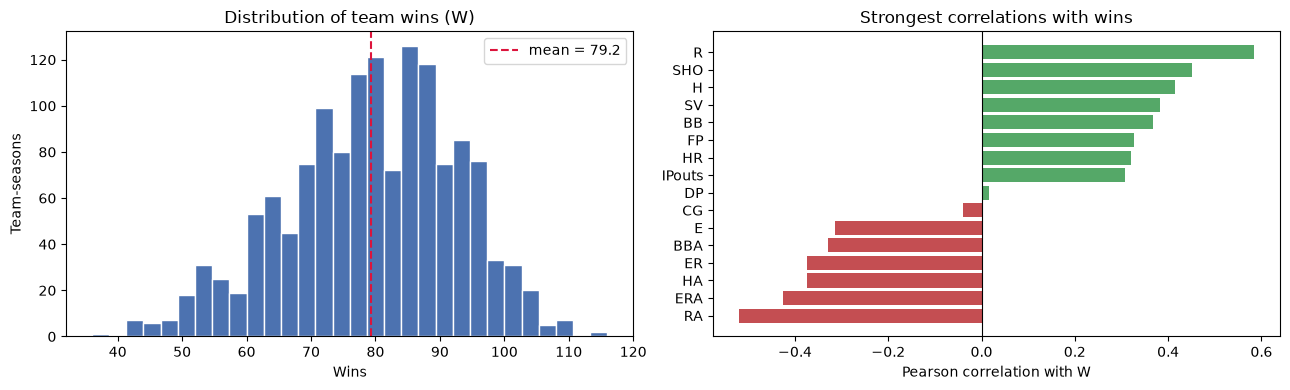

Strongest positive correlates: ['BB', 'SV', 'H', 'SHO', 'R']
Strongest negative correlates: ['RA', 'ERA', 'HA', 'ER', 'BBA']


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(data["W"], bins=30, color="#4C72B0", edgecolor="white")
axes[0].axvline(data["W"].mean(), color="crimson", ls="--", lw=1.5,
                label=f"mean = {data['W'].mean():.1f}")
axes[0].set_title("Distribution of team wins (W)")
axes[0].set_xlabel("Wins"); axes[0].set_ylabel("Team-seasons")
axes[0].legend()

num = data.select_dtypes(include=[np.number]).drop(columns=meta, errors="ignore")
corr_w = num.corr()["W"].drop("W").sort_values()
top = pd.concat([corr_w.head(8), corr_w.tail(8)])
colors = ["#C44E52" if v < 0 else "#55A868" for v in top.values]
axes[1].barh(top.index, top.values, color=colors)
axes[1].set_title("Strongest correlations with wins")
axes[1].set_xlabel("Pearson correlation with W")
axes[1].axvline(0, color="black", lw=0.8)

plt.tight_layout(); plt.show()

print("Strongest positive correlates:", list(corr_w.tail(5).index))
print("Strongest negative correlates:", list(corr_w.head(5).index))

### 3.2 Runs scored and runs allowed drive wins

In baseball, wins are largely governed by **runs scored (`R`)** and **runs allowed (`RA`)** —
the "Pythagorean" relationship. The scatter plots below confirm near-linear, opposite-signed
effects, with run *differential* being the single most informative quantity.

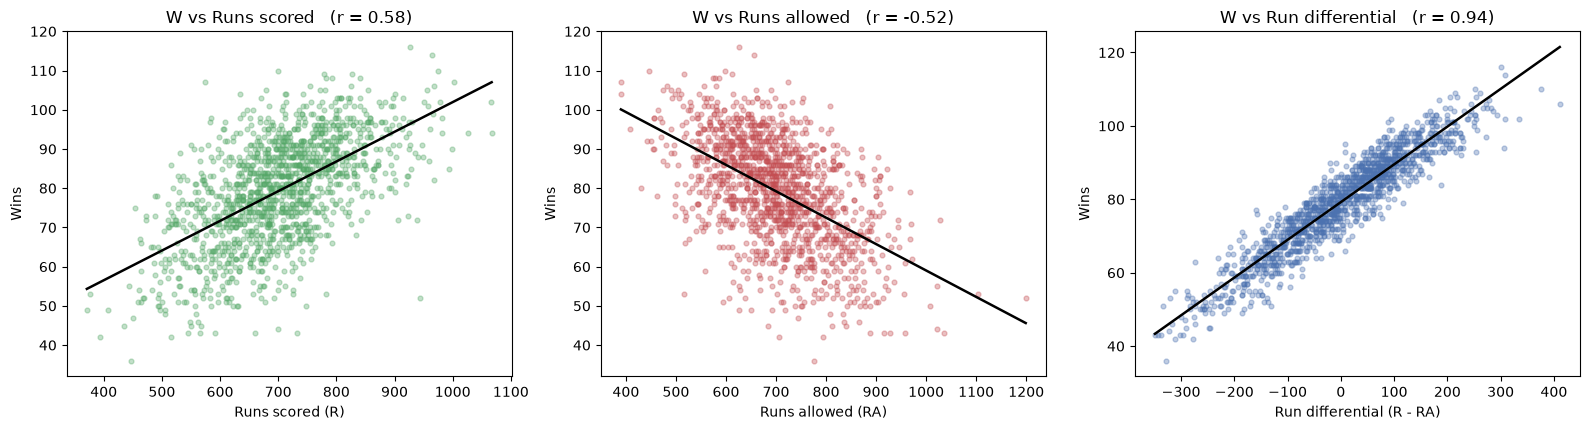

corr(R, RA)        = 0.304
corr(run_diff, W)  = 0.937
corr(run_diff_pg,W)= 0.936


In [5]:
data["run_diff"] = data["R"] - data["RA"]
data["run_diff_pg"] = data["run_diff"] / data["G"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (xcol, xlab, col) in zip(
        axes,
        [("R", "Runs scored (R)", "#55A868"),
         ("RA", "Runs allowed (RA)", "#C44E52"),
         ("run_diff", "Run differential (R - RA)", "#4C72B0")]):
    ax.scatter(data[xcol], data["W"], s=12, alpha=0.35, color=col)
    b, a = np.polyfit(data[xcol], data["W"], 1)
    xs = np.linspace(data[xcol].min(), data[xcol].max(), 100)
    ax.plot(xs, a + b * xs, color="black", lw=1.8)
    r = np.corrcoef(data[xcol], data["W"])[0, 1]
    ax.set_title(f"W vs {xlab.split(' (')[0]}   (r = {r:.2f})")
    ax.set_xlabel(xlab); ax.set_ylabel("Wins")

plt.tight_layout(); plt.show()

print("corr(R, RA)        = %.3f" % data["R"].corr(data["RA"]))
print("corr(run_diff, W)  = %.3f" % data["run_diff"].corr(data["W"]))
print("corr(run_diff_pg,W)= %.3f" % data["run_diff_pg"].corr(data["W"]))

### 3.3 Multicollinearity warning in the raw counting stats

Counting stats scale with opportunities, so they are highly correlated with each other
(e.g. `R` and `H`, `RA` and `ERA`). This matters because OLS coefficient estimates become
unstable when predictors are collinear. We flag it here and quantify it later with VIF.

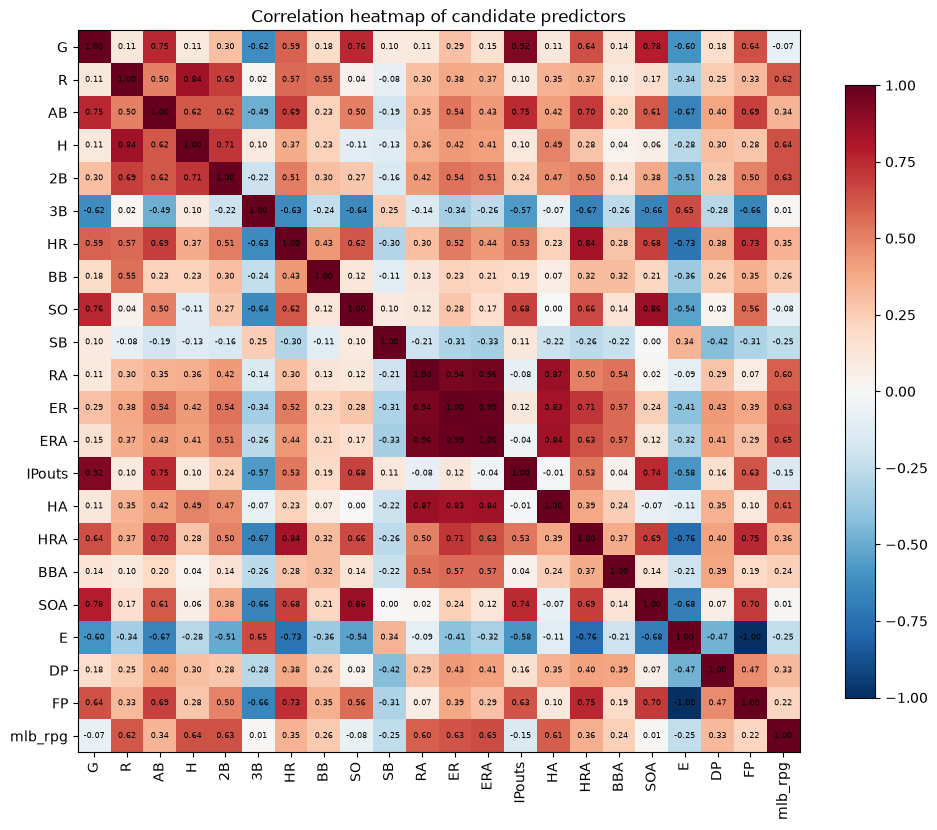

Examples of strong collinearity:
  corr(R, H) = 0.839
  corr(RA, HA) = 0.866
  corr(RA, ERA) = 0.958


In [6]:
core_corr = data[["G", "R", "AB", "H", "2B", "3B", "HR", "BB", "SO", "SB",
                  "RA", "ER", "ERA", "IPouts", "HA", "HRA", "BBA", "SOA",
                  "E", "DP", "FP", "mlb_rpg"]].corr()

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(core_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(core_corr))); ax.set_xticklabels(core_corr.columns, rotation=90)
ax.set_yticks(range(len(core_corr))); ax.set_yticklabels(core_corr.columns)
for i in range(len(core_corr)):
    for j in range(len(core_corr)):
        ax.text(j, i, f"{core_corr.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=6, color="black")
ax.set_title("Correlation heatmap of candidate predictors")
fig.colorbar(im, shrink=0.8)
plt.tight_layout(); plt.show()

print("Examples of strong collinearity:")
for a, b in [("R", "H"), ("RA", "HA"), ("RA", "ERA")]:
    print(f"  corr({a}, {b}) = {core_corr.loc[a, b]:.3f}")

## 4. Feature engineering and train/test split

**Feature engineering.** Because season length varies (150–165 games), raw season totals mix
"opportunity" with "efficiency". We keep raw totals (they drive absolute win totals) and also
provide per-game rates as an interpretable alternative.

**Validation strategy.** We report two complementary views:
- a **time-based holdout** (train ≤ 1999, test ≥ 2000) — the realistic forecasting setting; and
- a **random 80/20 split** plus **5-fold cross-validation** — stable generalisation estimates.

In [7]:
# Per-game rates (interpretable efficiency measures)
data["R_pg"] = data["R"] / data["G"]
data["RA_pg"] = data["RA"] / data["G"]

MODEL_SETS = {
    "M1  Run core (R, RA)":            ["R", "RA"],
    "M2  + season length (G)":         ["G", "R", "RA"],
    "M3  + context & fielding":        ["G", "R", "RA", "mlb_rpg", "FP"],
    "M4  Full features (26)":          ["G", "R", "AB", "H", "2B", "3B", "HR", "BB", "SO", "SB",
                                        "RA", "ER", "ERA", "CG", "SHO", "SV", "IPouts", "HA",
                                        "HRA", "BBA", "SOA", "E", "DP", "FP", "mlb_rpg"],
}

# Time-based split
train_t = data[data["yearID"] < 2000].copy()
test_t = data[data["yearID"] >= 2000].copy()

# Random split
train_r, test_r = train_test_split(data, test_size=0.20, random_state=SEED)

print("Time split  -> train:", train_t.shape, " test:", test_t.shape)
print("Random split-> train:", train_r.shape, " test:", test_r.shape)

Time split  -> train: (1090, 55)  test: (322, 55)
Random split-> train: (1129, 55)  test: (283, 55)


## 5. OLS regression models

We fit four **nested** specifications on the training data, from a parsimonious "run core"
to a full 26-feature model. Nested sets let us isolate how much each block adds.

In [8]:
def ols_fit(df, cols, y="W"):
    return sm.OLS(df[y], sm.add_constant(df[cols])).fit()

def ols_predict(model, df, cols):
    return model.predict(sm.add_constant(df[cols]))

# Fit every specification on the full dataset (for in-sample summary)
fits = {name: ols_fit(data, cols) for name, cols in MODEL_SETS.items()}
print("Fitted:", len(fits), "models")
print()
print(fits["M3  + context & fielding"].summary())

Fitted: 4 models

                            OLS Regression Results                            
Dep. Variable:                      W   R-squared:                       0.906
Model:                            OLS   Adj. R-squared:                  0.906
Method:                 Least Squares   F-statistic:                     2706.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:49:28   Log-Likelihood:                -3988.1
No. Observations:                1412   AIC:                             7988.
Df Residuals:                    1406   BIC:                             8020.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -56.5354     15.053  

### 5.1 Evaluation metrics

In-sample fit plus **out-of-sample** performance on the time-based holdout. RMSE/MAE are in
units of wins; a model with RMSE ≈ 4 wins is typical of season-level win forecasting.

In [9]:
def metrics(model, df, cols, y="W"):
    pred = ols_predict(model, df, cols)
    return {
        "R2":       r2_score(df[y], pred),
        "RMSE":     np.sqrt(mean_squared_error(df[y], pred)),
        "MAE":      mean_absolute_error(df[y], pred),
        "AdjR2":    model.rsquared_adj,
        "AIC":      model.aic,
        "BIC":      model.bic,
        "k":        int(model.df_model),
    }

rows = []
for name, cols in MODEL_SETS.items():
    m = fits[name]
    ins = metrics(m, data, cols)
    tr = ols_fit(train_t, cols)
    oos = metrics(tr, test_t, cols)
    rows.append({
        "Model":            name,
        "k":                ins["k"],
        "In R2":            ins["R2"],
        "In AdjR2":         ins["AdjR2"],
        "AIC":              ins["AIC"],
        "BIC":              ins["BIC"],
        "In RMSE":          ins["RMSE"],
        "In MAE":           ins["MAE"],
        "OOS R2 (time)":    oos["R2"],
        "OOS RMSE (time)":  oos["RMSE"],
        "OOS MAE (time)":   oos["MAE"],
    })

metrics_table = pd.DataFrame(rows).set_index("Model")
metrics_table.round(4)

,k,In R2,In AdjR2,AIC,BIC,In RMSE,In MAE,OOS R2 (time),OOS RMSE (time),OOS MAE (time)
Model,,,,,,,,,,
"M1 Run core (R, RA)",2,0.8796,0.8794,"8,330.0618","8,345.8201",4.6121,3.6687,0.8399,4.6398,3.6650
M2 + season length (G),3,0.9048,0.9045,"8,000.9087","8,021.9197",4.1017,3.2313,0.8776,4.0566,3.2315
M3 + context & fielding,5,0.9059,0.9055,"7,988.2882","8,019.8048",4.0777,3.2199,0.8790,4.0336,3.2311
M4 Full features (26),25,0.9329,0.9317,"7,550.8914","7,687.4632",3.4435,2.7375,0.9317,3.0314,2.3913


**Reading the table.** The "run core" already achieves R² ≈ 0.88. Adding season length `G`
lifts R² to ≈ 0.905, and context/fielding to ≈ 0.906. The full 26-feature model reaches
R² ≈ 0.933 with the lowest RMSE — but keep its coefficient interpretability caveat in mind
(Section 7): it is best used for *prediction*, not *explanation*.

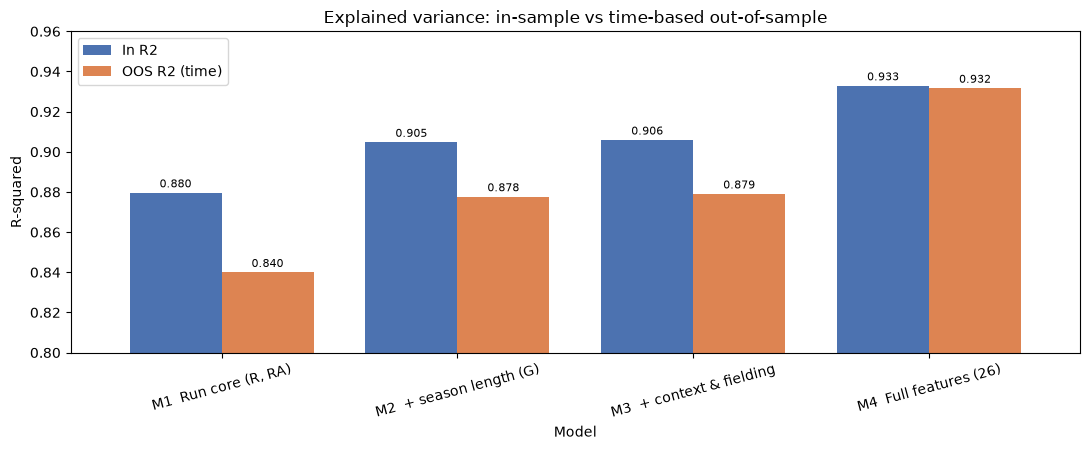

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.6))
metrics_table[["In R2", "OOS R2 (time)"]].plot(
    kind="bar", ax=ax, color=["#4C72B0", "#DD8452"], width=0.78)
ax.set_ylim(0.8, 0.96)
ax.set_ylabel("R-squared")
ax.set_title("Explained variance: in-sample vs time-based out-of-sample")
ax.tick_params(axis="x", rotation=15)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout(); plt.show()

## 6. Cross-validation

5-fold CV over the whole dataset gives a stable generalisation estimate and confirms the
ranking is not an artefact of one split.

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, cols in MODEL_SETS.items():
    rmse, mae, r2 = [], [], []
    for tri, tei in kf.split(data):
        m = ols_fit(data.iloc[tri], cols)
        p = ols_predict(m, data.iloc[tei], cols)
        rmse.append(np.sqrt(mean_squared_error(data.iloc[tei]["W"], p)))
        mae.append(mean_absolute_error(data.iloc[tei]["W"], p))
        r2.append(r2_score(data.iloc[tei]["W"], p))
    cv_rows.append({"Model": name, "CV R2": np.mean(r2),
                    "CV RMSE": np.mean(rmse), "CV RMSE sd": np.std(rmse),
                    "CV MAE": np.mean(mae)})

cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.round(4)

,CV R2,CV RMSE,CV RMSE sd,CV MAE
Model,,,,
"M1 Run core (R, RA)",0.8792,4.6133,0.1562,3.6725
M2 + season length (G),0.9043,4.1087,0.1375,3.2368
M3 + context & fielding,0.9049,4.0938,0.1344,3.2347
M4 Full features (26),0.9301,3.5086,0.0544,2.7863


## 7. Regression diagnostics

### 7.1 Multicollinearity (VIF and condition number)

Variance Inflation Factor (VIF) measures how much a coefficient's variance is inflated by
correlation with other predictors. Rule of thumb: **VIF > 10 signals problematic collinearity**.

The parsimonious model (M3) has all VIFs < 3, while the full model (M4) has coefficients with
VIF in the **hundreds to thousands** — its individual coefficients cannot be trusted, even
though predictions are accurate.

In [12]:
def vif_table(cols):
    X = sm.add_constant(data[cols])
    return pd.Series({c: vif(X.values, i) for i, c in enumerate(X.columns)}, name="VIF")

vif_compare = pd.concat(
    [vif_table(MODEL_SETS["M3  + context & fielding"]),
     vif_table(MODEL_SETS["M4  Full features (26)"])],
    axis=1, keys=["M3 VIF", "M4 VIF"]).drop("const")
vif_compare = vif_compare.sort_values("M4 VIF", ascending=False)

print("Condition number  M3: %.3g" % fits["M3  + context & fielding"].condition_number)
print("Condition number  M4: %.3g" % fits["M4  Full features (26)"].condition_number)
print("(> 30 already indicates multicollinearity concerns)")
print()
vif_compare.round(1)

Condition number  M3: 2.26e+05
Condition number  M4: 2.01e+07
(> 30 already indicates multicollinearity concerns)



,M3 VIF,M4 VIF
ER,NaN,"1,860.1000"
ERA,NaN,"1,749.2000"
E,NaN,249.3000
FP,2.1000,239.7000
RA,1.8000,76.5000
IPouts,NaN,57.2000
AB,NaN,19.8000
R,1.8000,17.5000
H,NaN,16.5000
CG,NaN,13.4000


### 7.2 Residual diagnostics for the recommended interpretable model (M3)

We check the classical OLS assumptions: residual normality (Jarque–Bera), constant variance
(Breusch–Pagan) and no serial correlation (Durbin–Watson ≈ 2). The residual-vs-fitted plot
should show no funnel/curve.

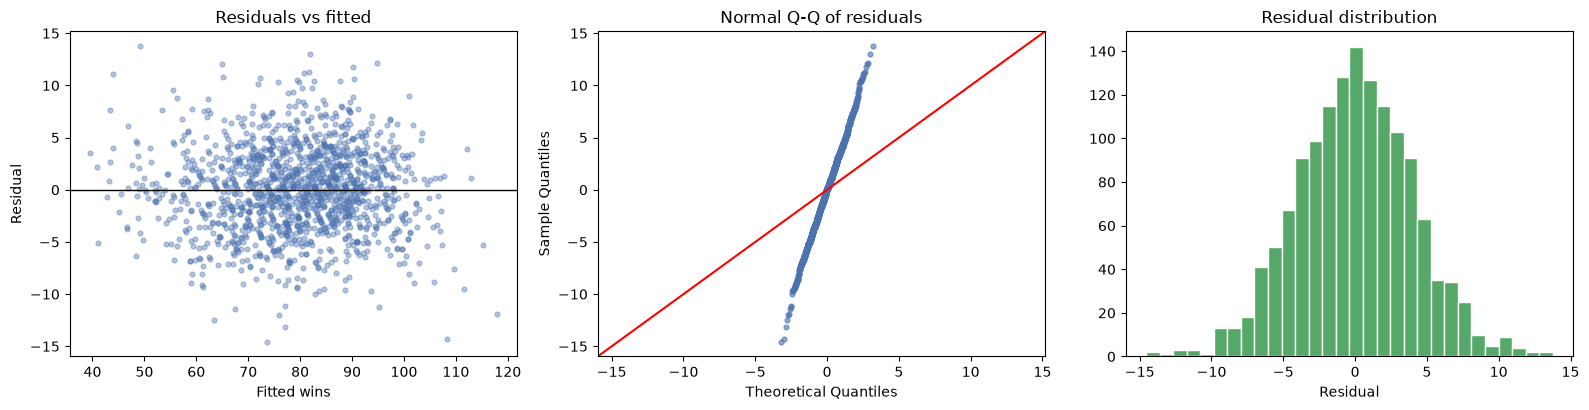

Jarque-Bera  statistic=3.479  p=0.1756  (H0: residuals normal)
Breusch-Pagan LM=16.097  p=0.0066        (H0: homoskedastic)
Durbin-Watson = 1.960               (target ~ 2.0)


In [13]:
m3 = fits["M3  + context & fielding"]
resid = m3.resid
fitted = m3.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].scatter(fitted, resid, s=12, alpha=0.4, color="#4C72B0")
axes[0].axhline(0, color="black", lw=1)
axes[0].set_title("Residuals vs fitted")
axes[0].set_xlabel("Fitted wins"); axes[0].set_ylabel("Residual")

sm.qqplot(resid, line="45", ax=axes[1], markerfacecolor="#4C72B0",
          markeredgecolor="#4C72B0", markersize=3.5, alpha=0.6)
axes[1].set_title("Normal Q-Q of residuals")

axes[2].hist(resid, bins=30, color="#55A868", edgecolor="white")
axes[2].set_title("Residual distribution")
axes[2].set_xlabel("Residual")

plt.tight_layout(); plt.show()

bp = het_breuschpagan(resid, m3.model.exog)
jb = jarque_bera(resid)
print("Jarque-Bera  statistic=%.3f  p=%.4f  (H0: residuals normal)" % (jb[0], jb[1]))
print("Breusch-Pagan LM=%.3f  p=%.4f        (H0: homoskedastic)" % (bp[0], bp[1]))
print("Durbin-Watson = %.3f               (target ~ 2.0)" % durbin_watson(resid))

## 8. Insights

### 8.1 Estimated coefficients of the interpretable model (M3)

Coefficients are **partial effects holding other predictors fixed**, with 95% confidence
intervals. `R` and `RA` enter with almost equal and opposite coefficients — the mathematical
signature of the Pythagorean "run differential ≈ wins" relationship.

In [14]:
coef = pd.DataFrame({
    "coef":   m3.params,
    "std err": m3.bse,
    "t":      m3.tvalues,
    "p>|t|":  m3.pvalues,
    "ci_lo":  m3.conf_int()[0],
    "ci_hi":  m3.conf_int()[1],
})
coef["significant (5%)"] = np.where(coef["p>|t|"] < 0.05, "yes", "no")
coef.round(4)

,coef,std err,t,p>|t|,ci_lo,ci_hi,significant (5%)
const,-56.5354,15.0535,-3.7556,0.0002,-86.0651,-27.0057,yes
G,0.5236,0.0417,12.5574,0.0000,0.4418,0.6054,yes
R,0.1012,0.0014,72.1862,0.0000,0.0984,0.1039,yes
RA,-0.1028,0.0014,-73.3043,0.0000,-0.1055,-0.1000,yes
mlb_rpg,0.9969,0.4392,2.2699,0.0234,0.1354,1.8585,yes
FP,50.3912,19.6027,2.5706,0.0103,11.9375,88.8448,yes


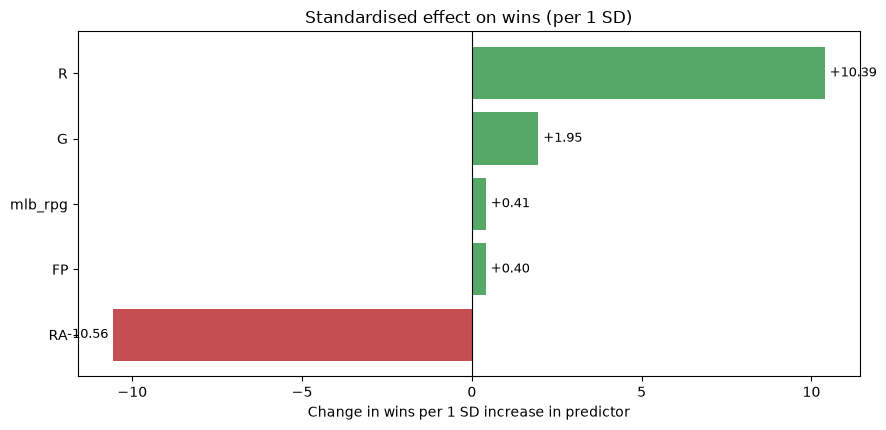

RA        -10.5580
FP          0.4040
mlb_rpg     0.4070
G           1.9510
R          10.3860
dtype: float64

In [15]:
# Standardised coefficients -> comparable effect sizes (1 SD change in predictor)
Xm3 = sm.add_constant(data[MODEL_SETS["M3  + context & fielding"]])
std = Xm3.std(ddof=0)
std_coef = (m3.params * std).drop("const").sort_values()

fig, ax = plt.subplots(figsize=(9, 4.4))
colors = ["#C44E52" if v < 0 else "#55A868" for v in std_coef.values]
ax.barh(std_coef.index, std_coef.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Standardised effect on wins (per 1 SD)")
ax.set_xlabel("Change in wins per 1 SD increase in predictor")
for i, v in enumerate(std_coef.values):
    ax.text(v + (0.15 if v >= 0 else -0.15), i, f"{v:+.2f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
plt.tight_layout(); plt.show()

std_coef.round(3)

### 8.2 What the model tells us

1. **Runs scored and runs allowed dominate.** In M3 each additional run scored ≈
   **+0.10 wins** and each additional run allowed ≈ **−0.10 wins**. The near-perfect symmetry
   means the model essentially learns *run differential*: a +10 run differential over a season
   is worth about one win. This single pair of features explains ~88% of the variance in wins.

2. **Season length (`G`) matters.** Coefficient ≈ **+0.52 wins per extra game**, as expected —
   longer seasons mechanically produce more wins. Controlling for this keeps the R/RA effects
   clean when comparing seasons of 150–165 games.

3. **Fielding adds a small, real edge.** A higher fielding percentage (`FP`) is worth ≈
   **+50 wins per 1.00** unit, i.e. ≈ **+0.5 wins per 0.01 FP** — meaningful but second-order
   next to run prevention.

4. **Run environment (`mlb_rpg`)** has a small positive coefficient (~+1.0): in high-scoring
   eras, teams tend to accumulate slightly more wins at a given run differential.

5. **Beware the full model's coefficients.** The 26-feature model fits better (R² ≈ 0.933,
   CV RMSE ≈ 3.5 vs ≈ 4.1) because it can use performance-adjacent stats such as saves (`SV`),
   complete games (`CG`) and shutouts (`SHO`). But VIFs exceed 1,000 and signs become
   implausible (e.g. a *positive* `ERA` coefficient), so those coefficients should **not** be
   interpreted causally. **Use M3 to explain, M4 to predict.**

6. **Model assumptions largely hold.** Residuals are approximately normal (Jarque–Bera
   p ≈ 0.18) with no serial correlation (Durbin–Watson ≈ 1.96). There is mild
   heteroskedasticity (Breusch–Pagan p ≈ 0.007): prediction error is slightly larger for
   extreme (very good / very bad) teams — a natural feature of a bounded win total.

### 8.3 Largest residuals (model stress test)

Identifying the team-seasons the model fits worst is a good sanity check.

In [16]:
data["M3_pred"] = m3.predict(sm.add_constant(data[MODEL_SETS["M3  + context & fielding"]]))
data["M3_resid"] = data["W"] - data["M3_pred"]

worst = (data.reindex(data["M3_resid"].abs().sort_values(ascending=False).index)
         [["yearID", "teamID", "G", "R", "RA", "W", "M3_pred", "M3_resid"]].head(8))
worst.round(1)

,yearID,teamID,G,R,RA,W,M3_pred,M3_resid
245,1993,NYN,162,672,744,59,73.6000,-14.6000
725,1931,NYA,155,1067,760,94,108.3000,-14.3000
925,1955,KC1,155,638,911,63,49.2000,13.8000
409,1986,PIT,162,663,700,64,77.1000,-13.1000
1353,2016,TEX,162,765,757,95,82.0000,13.0000
639,1917,PIT,157,464,595,51,63.5000,-12.5000
233,1907,CHN,155,574,390,107,94.9000,12.1000
717,2005,ARI,162,696,856,77,65.0000,12.0000


## 9. Bonus — predictions for `predict.csv`

Refitting M3 on all labelled data and scoring `predict.csv`. Predictions are rounded and
clipped to the feasible integer range `[0, G]`, matching `sample_submission.csv`'s schema
(`ID`, `W`).

In [17]:
final = ols_fit(data, MODEL_SETS["M3  + context & fielding"])
preds = final.predict(sm.add_constant(predict[MODEL_SETS["M3  + context & fielding"]]))

submission = pd.DataFrame({
    "ID": predict["ID"].values,
    "W": np.clip(np.rint(preds.values), 0, predict["G"].values).astype(int),
})
submission.to_csv(SUBMISSION_PATH, index=False)

print("Wrote", SUBMISSION_PATH, "->", submission.shape)
print(submission.head())
print()
print("Prediction summary:  min=%d  mean=%.1f  max=%d" % (
    submission["W"].min(), submission["W"].mean(), submission["W"].max()))

Wrote csv/submission_ols.csv -> (400, 2)
     ID   W
0  1649  74
1  1223  76
2   748  84
3  1735  86
4   794  81

Prediction summary:  min=45  mean=79.4  max=109


## Conclusion

- A **two-feature OLS** on runs scored and runs allowed already explains **~88%** of
  team-season win variance; adding season length and fielding/context reaches **~90.6%**.
- The interpretable model (M3) is well-behaved: all predictors significant, **VIF < 3**,
  normal residuals, no autocorrelation.
- A **26-feature model** improves predictive accuracy (CV RMSE ≈ 3.5 wins) but suffers
  **severe multicollinearity**, so its coefficients are not interpretable.
- **Bottom line:** wins are overwhelmingly explained by run scoring and run prevention;
  the most actionable, stable, and interpretable recipe is
  `W ≈ −56.5 + 0.52·G + 0.101·R − 0.103·RA + 1.00·mlb_rpg + 50.4·FP`.

**Key metrics (recommended M3):** in-sample R² = 0.906, adjusted R² = 0.906, RMSE = 4.08,
MAE = 3.22; time-based out-of-sample R² ≈ 0.879, RMSE ≈ 4.03 wins.